In [1]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.efficientnet_b0(weights=None)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    11
)

model.load_state_dict(torch.load("efficientnet_b0_best.pth", map_location=device))

model = model.to(device)

model.eval()

print("Model Loaded Successfully!")

Model Loaded Successfully!


In [14]:
import pandas as pd

val_df = pd.read_csv("val_split.csv")

print(val_df.head())
print("Validation Images :", len(val_df))
print(val_df["spoof_type"].value_counts())

                         image_path  spoof_type  illumination  environment  \
0  Data/train/9965/spoof/303859.jpg          10             1            2   
1  Data/train/7521/spoof/232839.jpg           8             1            1   
2  Data/train/7134/spoof/071886.jpg           7             4            2   
3  Data/train/5795/spoof/453867.jpg           6             4            1   
4   Data/train/3602/live/180389.jpg           0             0            0   

   live_spoof  
0           1  
1           1  
2           1  
3           1  
4           0  
Validation Images : 98881
spoof_type
0     32493
10     8123
1      7110
4      6729
6      6657
8      6617
3      6355
9      6305
2      6244
7      6215
5      6033
Name: count, dtype: int64


In [15]:
DATASET_ROOT = "CelebA_Spoof_/CelebA_Spoof"

val_dataset = CelebASpoofDataset(
    dataframe=val_df,
    root_dir=DATASET_ROOT,
    transform=test_transform
)

In [16]:
from torch.utils.data import DataLoader

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Validation Images :", len(val_dataset))
print("Validation Batches :", len(val_loader))

Validation Images : 98881
Validation Batches : 3091


In [17]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch

y_true = []
y_pred = []

model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)

print("=" * 60)
print(f"Validation Accuracy : {accuracy*100:.2f}%")
print("=" * 60)

Validation Accuracy : 99.94%


In [18]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(
    y_true,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Accuracy  : 0.9994
Precision : 0.9994
Recall    : 0.9994
F1 Score  : 0.9994


In [19]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     32493
           1       1.00      1.00      1.00      7110
           2       1.00      1.00      1.00      6244
           3       1.00      1.00      1.00      6355
           4       1.00      1.00      1.00      6729
           5       1.00      1.00      1.00      6033
           6       1.00      1.00      1.00      6657
           7       1.00      1.00      1.00      6215
           8       1.00      1.00      1.00      6617
           9       1.00      1.00      1.00      6305
          10       1.00      1.00      1.00      8123

    accuracy                           1.00     98881
   macro avg       1.00      1.00      1.00     98881
weighted avg       1.00      1.00      1.00     98881



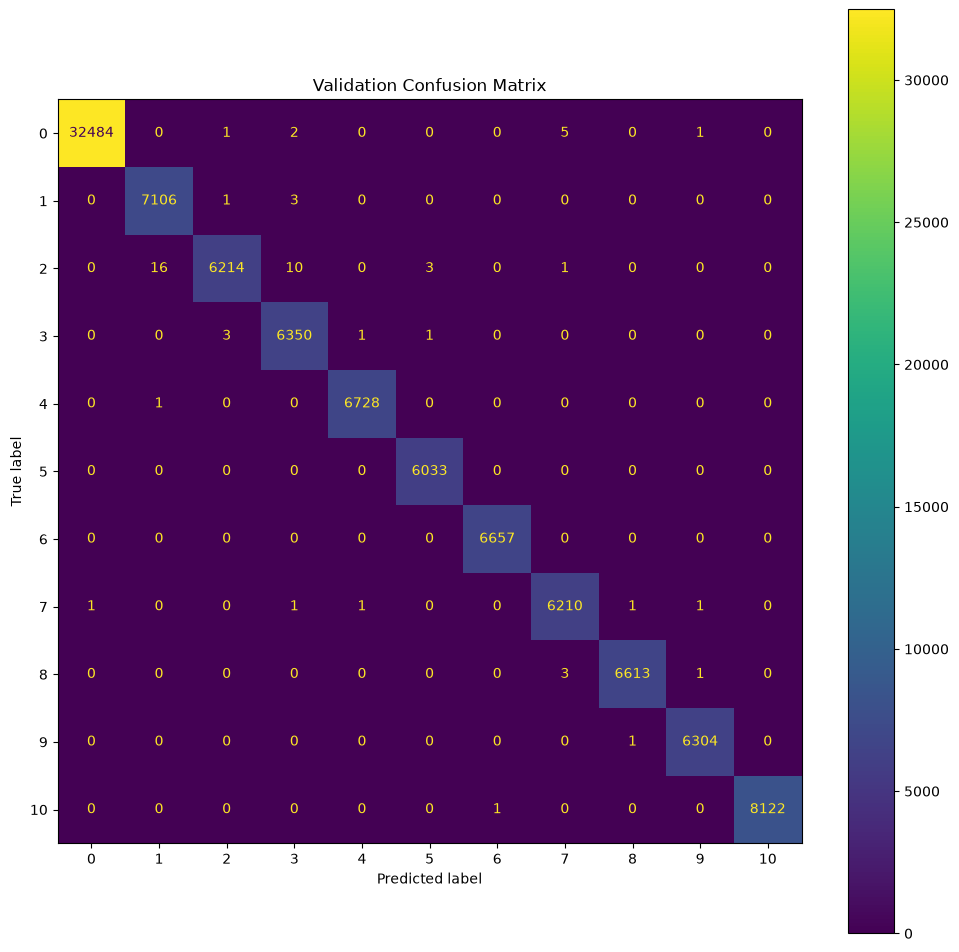

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(12, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(ax=ax)

plt.title("Validation Confusion Matrix")
plt.show()

In [21]:
import pandas as pd

train = pd.read_csv("train_split.csv")
val = pd.read_csv("val_split.csv")

overlap = set(train["image_path"]).intersection(set(val["image_path"]))

print("Overlapping images:", len(overlap))

Overlapping images: 0


In [1]:
import os
import pandas as pd

train_df = pd.read_csv("train_split.csv")
val_df = pd.read_csv("val_split.csv")

train_ids = set(train_df["image_path"].apply(lambda x: os.path.normpath(x).split(os.sep)[2]))
val_ids = set(val_df["image_path"].apply(lambda x: os.path.normpath(x).split(os.sep)[2]))

common_ids = train_ids.intersection(val_ids)

print("Common Subject IDs:", len(common_ids))

Common Subject IDs: 8162
